## PROCESAMIENTO TXT

El objetivo de este proyecto es efectuar un Análisis Explotario de Datos y algunos pasos previos de limpieza tales como:  
1.- Eliminar rellenar nulos con la media de la columna, 
2.- Contar total de registros faltantes por fecha

## Paso 1: Carga y Estructuración de los Datos

En esta primera etapa, tomamos el archivo de texto sin procesar (`25001.txt`) que contiene los registros diarios de la estación meteorológica y lo transformamos en una tabla estructurada (similar a una hoja de Excel) para poder analizarlo.

Para asegurar que la información se importe correctamente desde el principio, aplicamos los siguientes filtros durante la carga:
* **Limpieza inicial:** El archivo original contiene texto introductorio y notas finales que no son mediciones. Configuramos el sistema para ignorar estas líneas y evitar que la tabla se deforme.
* **Asignación de encabezados:** Nombramos las columnas para identificar claramente cada medición: Fecha, Precipitación (PRECIP), Evaporación (EVAP), Temperatura Máxima (TMAX) y Temperatura Mínima (TMIN).
* **Detección de información faltante:** Le indicamos al programa que la palabra "Nulo" representa una falla en la medición de ese día. Al detectarla, el sistema la convertirá automáticamente en un espacio vacío oficial, lo cual es crucial para no arruinar nuestros cálculos matemáticos más adelante.
* **Ajuste de lectura:** Configuramos la lectura para que reconozca cualquier caracter especial del español y alinee correctamente las columnas sin importar cuántos espacios en blanco haya entre ellas.

Finalmente, visualizamos las primeras cinco filas de nuestra nueva tabla para confirmar que los datos se estructuraron de manera exitosa.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
df=pd.read_csv('25001.txt',
skiprows=21, 
skipfooter=2,
names=['FECHA','PRECIP','EVAP','TMAX','TMIN'] , 
sep=r'\s+',
na_values='Nulo',
encoding='latin1', 
    engine='python'
) 
df.head()

,FECHA,PRECIP,EVAP,TMAX,TMIN
0,03/01/1961,0.0,NaN,31.0,11.0
1,04/01/1961,0.0,NaN,32.0,13.0
2,05/01/1961,0.0,NaN,29.0,14.0
3,06/01/1961,0.0,NaN,24.0,14.5
4,07/01/1961,0.0,NaN,28.5,10.0


## Paso 2: Identificación y Conteo de Datos Faltantes

Antes de proceder a rellenar los huecos en nuestra base de datos, es fundamental realizar un diagnóstico para saber exactamente cuánta información se perdió y en qué días específicos ocurrió. 

Para lograr esto, diseñamos un proceso de revisión automatizado que realiza lo siguiente:
* **Estandarización del calendario:** Primero, nos aseguramos de que el sistema reconozca la columna de fechas como un calendario real y no solo como texto, lo que nos permite mantener un orden cronológico perfecto.
* **Escaneo diario (Fila por fila):** El programa analiza cada día registrado y cuenta cuántos sensores fallaron. Es decir, suma cuántos espacios vacíos existen entre las cuatro variables principales (Lluvia, Evaporación y ambas Temperaturas) para una misma fecha.
* **Filtrado de anomalías:** Descartamos temporalmente todos los días que tienen registros perfectos para aislar y agrupar únicamente aquellos días que presentan al menos un dato faltante.
* **Generación del reporte:** Finalmente, creamos una tabla de resumen limpia que nos muestra la fecha exacta del fallo y la cantidad de variables que no se registraron ese día. 

El resultado de esta operación nos imprimirá el número total de días afectados en toda la historia de la estación y nos mostrará la tabla detallada.

In [ ]:
def DatosFaltantes(df):
    
    df['FECHA'] = pd.to_datetime(df['FECHA'], dayfirst=True)
    df['FECHA'] = df['FECHA'].dt.date 
    columnas_clima = ['PRECIP', 'EVAP', 'TMAX', 'TMIN']   
    df['VARIABLES_NULAS'] = df[columnas_clima].isnull().sum(axis=1)
    dias_incompletos = df[df['VARIABLES_NULAS'] > 0]
    tabla_resumen = dias_incompletos[['FECHA', 'VARIABLES_NULAS']]    
    print(f"Dias con registros nulos en la tabla: {len(tabla_resumen)}")
    return tabla_resumen

# Ejecucion del metodo
DatosFaltantes(df)

Dias con registros nulos en la tabla: 310


,FECHA,VARIABLES_NULAS
0,1961-01-03,1
1,1961-01-04,1
2,1961-01-05,1
3,1961-01-06,1
4,1961-01-07,1
...,...,...
18926,2016-07-23,1
18928,2016-07-25,1
19208,2017-06-01,1
19325,2017-09-26,1


## Paso 3: Análisis Histórico de Fallas (Agrupación por Año)

Saber cuántos días faltan en total es útil, pero para un Análisis Exploratorio de Datos profundo, necesitamos entender el **comportamiento histórico** de esas fallas. No es lo mismo que falten 30 días dispersos a lo largo de 50 años, a que falte un mes entero consecutivo porque un sensor se descompuso.

Para investigar esto, creamos una función que evalúa la calidad de los datos a través del tiempo:
* **Extracción del Año:** A partir de la fecha exacta, extraemos únicamente el año para poder tener una vista panorámica (macro) del registro histórico.
* **Agrupación anual de errores:** El programa agrupa todo el historial por años y suma cuántos datos faltaron en cada variable específica. Esto nos permite identificar rápidamente si hubo "años críticos" donde la estación meteorológica dejó de funcionar o si algún instrumento en particular (como el medidor de evaporación) tuvo problemas constantes durante una década.
* **Balance global:** Al final, generamos un conteo total definitivo de cuántos vacíos existen en cada categoría. 

Esta perspectiva histórica nos da la confianza necesaria para proceder a rellenar los datos, sabiendo exactamente a qué nos enfrentamos.

In [ ]:
def nulos(df_temp):
    df_temp['FECHA'] = pd.to_datetime(df_temp['FECHA'], dayfirst=True)
    df_temp['Año'] = df_temp['FECHA'].dt.year
    cols_clima = ['PRECIP', 'EVAP', 'TMAX', 'TMIN']
    nulos_por_anio = df_temp[cols_clima].isnull().groupby(df_temp['Año']).sum()   
    print("--- Cantidad de datos nulos detectados por Año ---")
    display(nulos_por_anio)
    print("\nTotal de nulos en todo el registro:")    
    print(df_temp[cols_clima].isnull().sum())

    return df_temp
df = nulos(df)

--- Cantidad de datos nulos detectados por Año ---


,PRECIP,EVAP,TMAX,TMIN
Año,,,,
1961,0,59,0,0
1962,0,2,0,0
1963,0,4,0,0
1964,1,0,0,0
1965,0,4,0,0
1966,1,3,0,0
1967,0,2,0,0
1968,0,1,0,0
1969,30,1,1,1



Total de nulos en todo el registro:
PRECIP     40
EVAP      270
TMAX        5
TMIN        6
dtype: int64


## Transformación y Limpieza de Formatos (Preparación de los Datos)

Después de la carga inicial del archivo de texto, es muy común que los datos en bruto traigan "basura" escondida. A veces los reportes meteorológicos incluyen encabezados adicionales en medio de la página, guiones o letras capturadas por error. Para que nuestras fórmulas matemáticas funcionen más adelante, necesitamos purificar la estructura de la tabla:

* **Validación de Fechas y Eliminación de Basura:** Forzamos al sistema a leer la primera columna bajo un formato estricto de calendario. Si el sistema detecta que una fila contiene texto que no tiene sentido como fecha (por ejemplo, un título colado), la invalida y elimina esa fila por completo. Esto nos asegura que solo trabajaremos con registros de días reales.
* **Conversión Matemática (Texto a Números):** En los archivos de texto, la computadora suele interpretar un número como "32.5" simplemente como una palabra. En este paso, seleccionamos todas las columnas de medición de clima y obligamos al sistema a convertirlas en valores numéricos decimales. Si había algún espacio extra o letra pegada a un número, el sistema lo neutralizará.

Con este filtro aplicado, nuestra tabla deja de ser solo un montón de texto importado y se convierte en una base de datos matemática, lista para ser procesada estadísticamente.

In [ ]:
def transformacion(df_temp):
   
    df_temp['FECHA'] = pd.to_datetime(df_temp['FECHA'], dayfirst=True, errors='coerce')

    df_temp = df_temp.dropna(subset=['FECHA'])

    cols_num = ['PRECIP', 'EVAP', 'TMAX', 'TMIN']
    df_temp[cols_num] = df_temp[cols_num].apply(pd.to_numeric, errors='coerce') 
    
    return df_temp

df = transformacion(df)
df.head()

,FECHA,PRECIP,EVAP,TMAX,TMIN,VARIABLES_NULAS,Año
0,1961-01-03,0.0,NaN,31.0,11.0,1,1961
1,1961-01-04,0.0,NaN,32.0,13.0,1,1961
2,1961-01-05,0.0,NaN,29.0,14.0,1,1961
3,1961-01-06,0.0,NaN,24.0,14.5,1,1961
4,1961-01-07,0.0,NaN,28.5,10.0,1,1961


## Paso 4: Imputación de Datos (Relleno con Promedios)

Ya identificamos y contamos la información faltante. Sin embargo, no podemos simplemente borrar esos días defectuosos, ya que perderíamos la continuidad del calendario histórico. Tampoco podemos dejar las celdas vacías porque generarían errores en las gráficas y análisis futuros. La solución técnica es la **imputación de datos**.

Para este proyecto, aplicamos el método de imputación por media aritmética:
* **Cálculo del Promedio:** El sistema calcula automáticamente cuál fue el valor promedio general de cada variable (cuánta lluvia cae en promedio, cuál es la temperatura media histórica, etc.).
* **Relleno Quirúrgico:** Una vez obtenidos esos promedios, el programa busca exclusivamente las celdas vacías (los nulos que detectamos antes) y les inyecta el valor promedio correspondiente a su columna. Es un proceso seguro que no altera ni modifica las mediciones reales que sí fueron capturadas correctamente por los sensores.
* **Comprobación Final:** Como último paso de control de calidad, le pedimos al sistema que vuelva a hacer un conteo total de vacíos. El resultado en pantalla debe mostrar ceros en todas las columnas, demostrando matemáticamente que nuestra base de datos ha quedado 100% limpia y lista para graficarse.

In [ ]:
def limpieza(df_temp):
    cols_num = ['PRECIP', 'EVAP', 'TMAX', 'TMIN']
    
    df_temp[cols_num] = df_temp[cols_num].fillna(df_temp[cols_num].mean())
    
    return df_temp

df = limpieza(df)
df.isnull().sum()

FECHA              0
PRECIP             0
EVAP               0
TMAX               0
TMIN               0
VARIABLES_NULAS    0
Año                0
dtype: int64

## Paso 5: Resumen Estadístico (Análisis Exploratorio Final)

Ahora que nuestra base de datos está completamente limpia, sin texto basura y sin espacios vacíos, podemos extraer el verdadero valor de la información. En este paso generamos un resumen matemático que nos permite entender el comportamiento general del clima histórico en la estación Acatitán.

Para lograrlo, diseñamos una función que extrae las siguientes métricas:
* **Panorama General:** Generamos un reporte estadístico completo que incluye conteos, desviaciones estándar y cuartiles de todas las variables climáticas.
* **Métricas Clave Simplificadas:** Para facilitar la interpretación a cualquier usuario, extraemos una segunda tabla enfocada solo en los cuatro indicadores más importantes:
    * **Media y Mediana:** Nos ayudan a conocer el clima "típico" o normal de la región, dándonos el punto de equilibrio de las lluvias y las temperaturas.
    * **Valores Máximos y Mínimos:** Nos revelan los extremos históricos absolutos. Gracias a esto, podemos identificar a simple vista la temperatura más helada registrada, el día más caluroso, o la tormenta más fuerte.

Esta tabla final resume años de registros meteorológicos en unas cuantas cifras directas y fáciles de interpretar, concluyendo la etapa analítica antes de pasar a la visualización gráfica.

In [ ]:
def datos(df_temp):
    cols_num = ['PRECIP', 'EVAP', 'TMAX', 'TMIN']
    
    print("RESUMEN ESTADÍSTICO")
    display(df_temp[cols_num].describe())
    
    print("\n--- MÉTRICAS ESPECÍFICAS SOLICITADAS ---")
    stats_resumen = pd.DataFrame({
        'Media (Promedio)': df_temp[cols_num].mean(), # Calculamos la media de cada columna numérica
        'Mediana': df_temp[cols_num].median(), # Calculamos la mediana de cada columna numérica
        'Valor máximo': df_temp[cols_num].max(), # Calculamos el valor máximo de cada columna numérica
        'Valor mínimo': df_temp[cols_num].min() # Calculamos el valor mínimo de cada columna numérica
    })
    display(stats_resumen)

# Ejecutamos el análisis final
datos(df)

--- RESUMEN ESTADÍSTICO ---


,PRECIP,EVAP,TMAX,TMIN
count,19571.000000,19571.000000,19571.000000,19571.000000
mean,2.217690,4.882219,34.469672,16.657470
std,9.007227,2.263605,3.428847,6.247926
min,0.000000,0.000000,18.000000,-2.500000
25%,0.000000,3.200000,32.500000,11.000000
50%,0.000000,4.600000,35.000000,16.500000
75%,0.000000,6.400000,37.000000,23.000000
max,217.400000,15.600000,45.500000,29.000000



--- MÉTRICAS ESPECÍFICAS SOLICITADAS ---


,Media (Promedio),Mediana,Valor máximo,Valor mínimo
PRECIP,2.217690,0.0,217.4,0.0
EVAP,4.882219,4.6,15.6,0.0
TMAX,34.469672,35.0,45.5,18.0
TMIN,16.657470,16.5,29.0,-2.5


VISUALIZACIÓN## Paso 6: Visualización de Datos (Análisis Exploratorio Visual)

Las tablas y resúmenes estadísticos son útiles, pero la forma más efectiva de identificar patrones climáticos es a través de representaciones gráficas. En esta etapa final, utilizamos las librerías de visualización para proyectar el comportamiento del clima en Acatitán.

Hemos dividido nuestro análisis visual en dos enfoques:

**1. Distribución Histórica (Histogramas)**
Estas gráficas nos muestran con qué frecuencia ocurren ciertos eventos climáticos:
* **Temperaturas (TMAX y TMIN):** Observamos dónde se concentra el calor y el frío. Las curvas nos indican visualmente los rangos térmicos más comunes y nos permiten ver la frecuencia de los días con temperaturas extremas.
* **Precipitación:** Para no sesgar la gráfica con la enorme cantidad de días secos del año, filtramos la vista para analizar únicamente los días en que sí llovió. Esto nos permite ver el volumen típico de las tormentas en la zona.

**2. Relación entre Variables (Gráficos de Dispersión)**
Estas gráficas nos ayudan a confirmar hipótesis sobre cómo interactúa el clima:
* **Amplitud Térmica (TMIN vs TMAX):** Comparamos las mañanas más frías contra las tardes más calurosas para ver si existe un patrón de calentamiento diario constante.
* **Efecto de Evaporación (TMAX vs EVAP):** Visualizamos la relación directa entre los picos de calor y la cantidad de agua que se evapora, un dato crítico para la agricultura y la gestión del agua en la región.

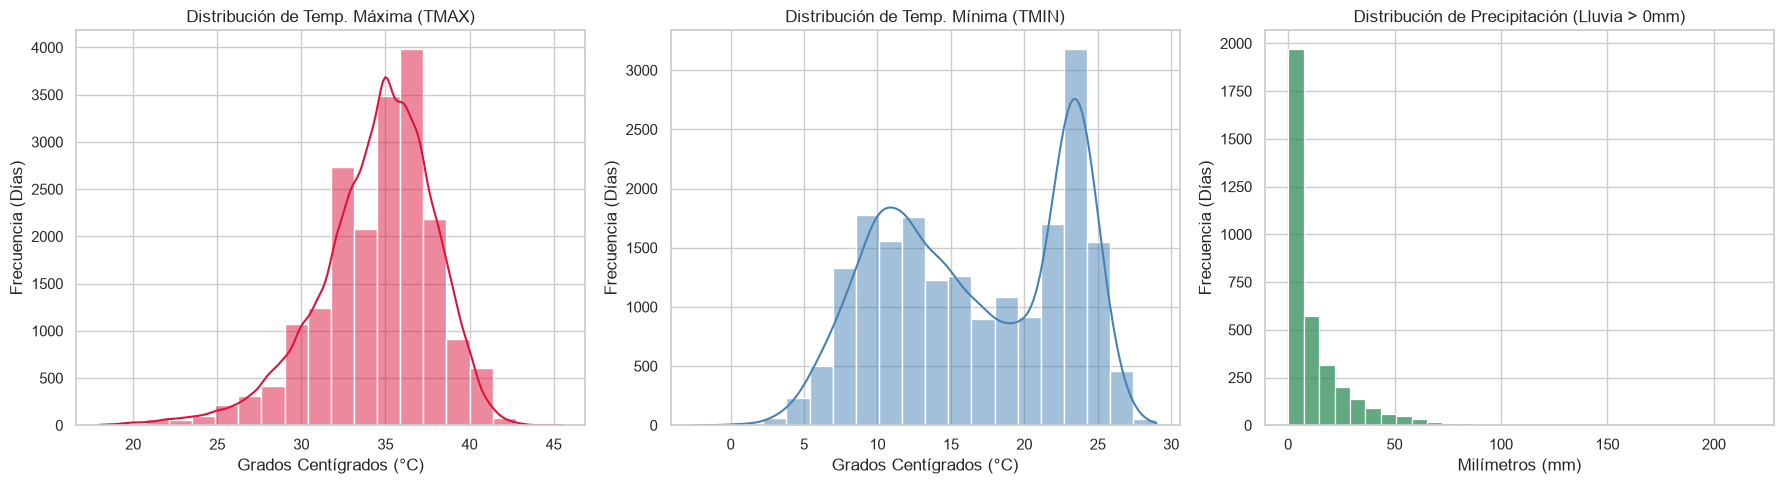

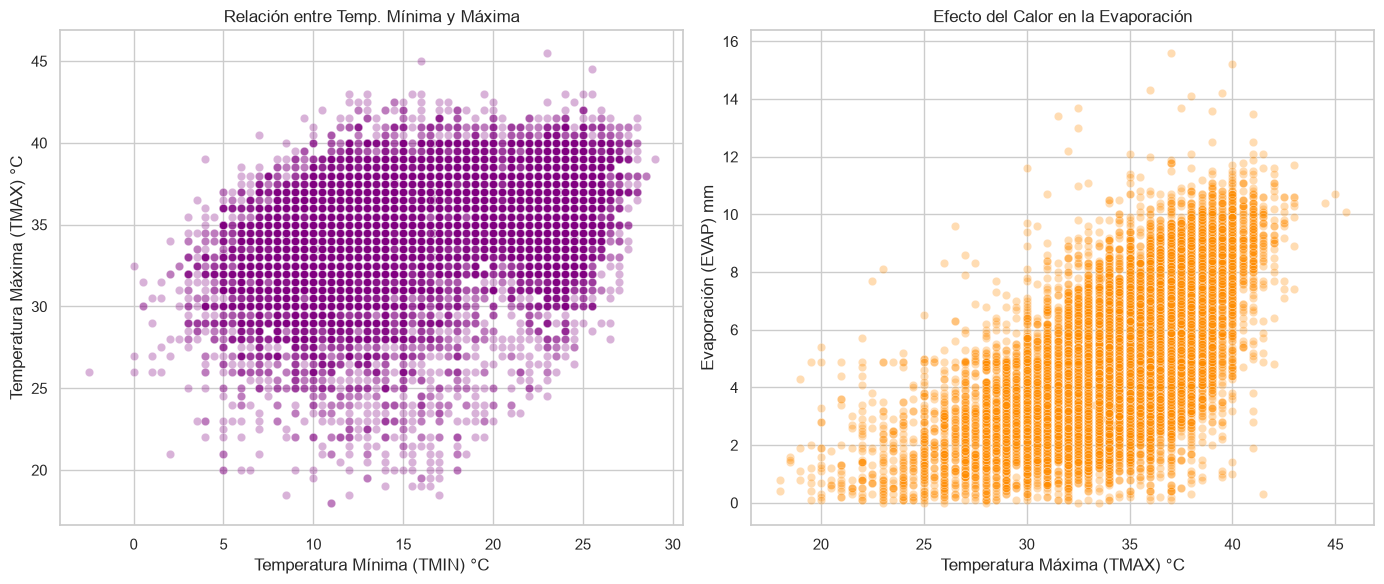

In [ ]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histograma de Temperatura Máxima (TMAX)
sns.histplot(df['TMAX'], bins=20, kde=True, color='crimson', ax=axes[0])
axes[0].set_title('Distribución de Temp. Máxima (TMAX)')
axes[0].set_xlabel('Grados Centígrados (°C)')
axes[0].set_ylabel('Frecuencia (Días)')

# 2. Histograma de Temperatura Mínima (TMIN)
sns.histplot(df['TMIN'], bins=20, kde=True, color='steelblue', ax=axes[1])
axes[1].set_title('Distribución de Temp. Mínima (TMIN)')
axes[1].set_xlabel('Grados Centígrados (°C)')
axes[1].set_ylabel('Frecuencia (Días)')

# 3. Histograma de Precipitación (Días de lluvia)
# Filtramos los datos para ver solo los días que sí llovió (>0)
dias_con_lluvia = df[df['PRECIP'] > 0]
sns.histplot(dias_con_lluvia['PRECIP'], bins=30, kde=False, color='seagreen', ax=axes[2])
axes[2].set_title('Distribución de Precipitación (Lluvia > 0mm)')
axes[2].set_xlabel('Milímetros (mm)')
axes[2].set_ylabel('Frecuencia (Días)')

# Ajustamos los espacios automáticamente y renderizamos
plt.tight_layout()
plt.show()

# Creamos una figura con 2 subgráficos (1 fila, 2 columnas)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. Gráfico de dispersión: TMIN vs TMAX
sns.scatterplot(x='TMIN', y='TMAX', data=df, alpha=0.3, color='purple', ax=axes[0])
axes[0].set_title('Relación entre Temp. Mínima y Máxima')
axes[0].set_xlabel('Temperatura Mínima (TMIN) °C')
axes[0].set_ylabel('Temperatura Máxima (TMAX) °C')

# 2. Gráfico de dispersión: TMAX vs EVAP
sns.scatterplot(x='TMAX', y='EVAP', data=df, alpha=0.3, color='darkorange', ax=axes[1])
axes[1].set_title('Efecto del Calor en la Evaporación')
axes[1].set_xlabel('Temperatura Máxima (TMAX) °C')
axes[1].set_ylabel('Evaporación (EVAP) mm')

# Ajustamos los espacios automáticamente y renderizamos
plt.tight_layout()
plt.show()